# Rasterio

In [1]:
import os
import numpy as np
import rasterio as rio
from rasterio.plot import show, show_hist

print(rio.__version__)

1.5.2


## Odpiranje rastra

In [6]:
dem_path=os.path.normpath(r"C:\KODA\Python\Rasterio\Pivola.tif")

with rio.open(dem_path) as src:
    print(src.count)     #število kanalov (1 ker je dem)
    print(src.meta)      #meta podatki
    band=src.read(1)
    print(type(band))   #kanal je shranjen kot array
    print(band)

1
{'driver': 'GTiff', 'dtype': 'float32', 'nodata': 9999.0, 'width': 4000, 'height': 4000, 'count': 1, 'crs': CRS.from_wkt('PROJCS["ETRS89-SVN [D96] / Slovene National Grid",GEOGCS["ETRS89-SVN [D96]",DATUM["Slovenia_Geodetic_Datum_1996",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6765"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4765"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",15],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",-5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","3794"]]'), 'transform': Affine(0.5, 0.0, 548000.0,
       0.0, -0.5, 153000.49)}
<class 'numpy.ndarray'>
[[369.0252  368.90106 368.63956 ... 272.79684 272.7977  272.79935]
 [368.81174 368.63867 368.4972  ... 272.78122 272.771   2

## Prikaz rastra

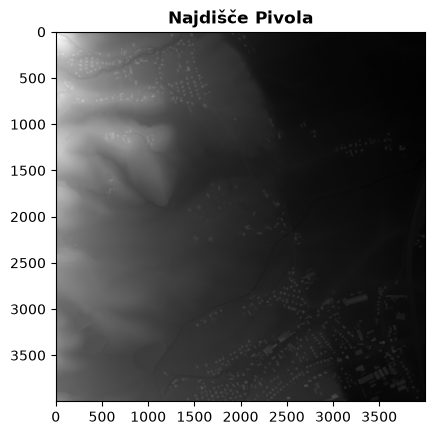

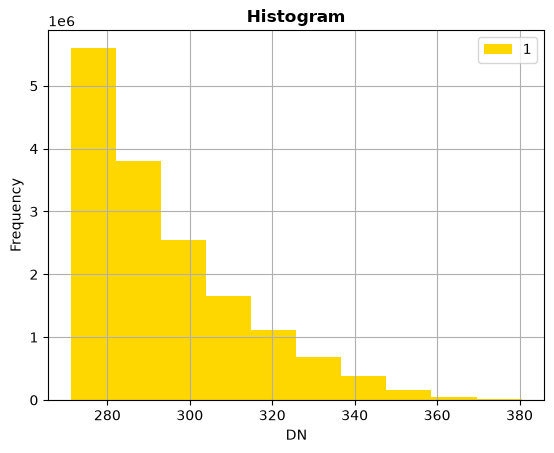

In [ ]:
show(band,title="Najdišče Pivola", cmap="gray")
show_hist(band)  #za prikaz histograma

[[-1.8488159e+00 -1.9060974e+00 -1.8838501e+00 ... -4.3640137e-03
  -6.5307617e-03  1.1444092e-02]
 [-2.0512695e+00 -2.1433411e+00 -2.1957703e+00 ...  1.5411377e-02
  -6.7749023e-03  1.1901855e-03]
 [-2.2781677e+00 -2.3053284e+00 -2.2629089e+00 ... -1.4221191e-02
   3.6010742e-03  5.1544189e-02]
 ...
 [ 3.7216187e-01  3.7393188e-01  3.5586548e-01 ... -3.0792236e-02
  -4.3792725e-02 -6.6528320e-03]
 [ 4.0930176e-01  4.2102051e-01  4.1287231e-01 ... -2.7770996e-02
  -3.0761719e-02 -1.3702393e-02]
 [ 5.0814819e-01  4.9987793e-01  4.9169922e-01 ... -2.4780273e-02
  -2.7801514e-02 -2.0874023e-02]]


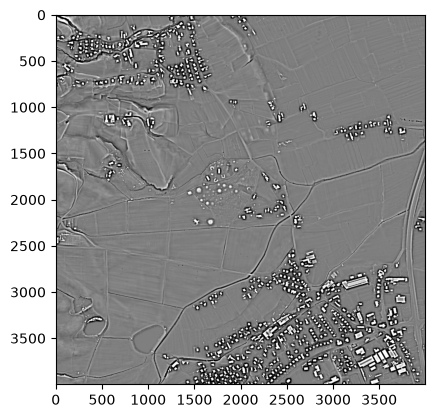

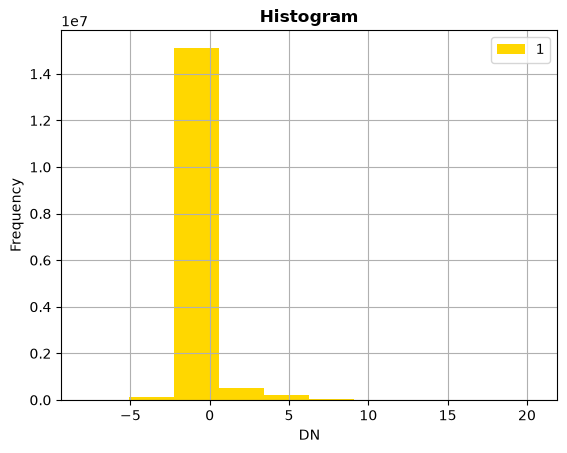

In [7]:

#Deluje isto za slrm
with rio.open(r"C:\KODA\Python\Rasterio\Pivola_SLRM_R20.tif")as src_slrm:
    slrm_band=src_slrm.read(1)

print(slrm_band)
show(slrm_band,cmap="gray", vmin=-1.5, vmax=1.5) # vmin in vmax za razteg histograma
show_hist(slrm_band)

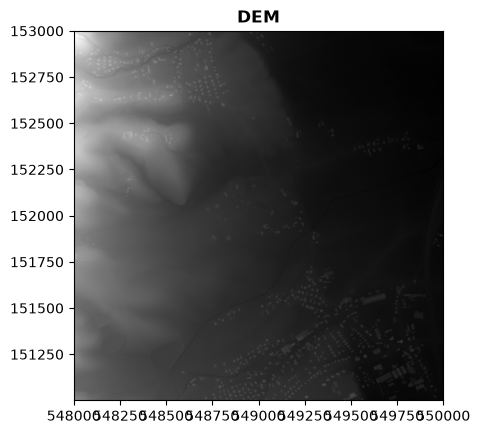

In [8]:
with rio.open(dem_path) as src:
    show(src,title="DEM", cmap="gray")  # če želimo prave koordinate, namreč izven open blocka se podatki zaprejo
    

## Transformiranje iz pixel koordinat v prostorke koordinate


### Iz pixel koordinat v prostorske
v rastru so višine (v primerudem-a) v arreyu. Da dobimo prostorske koordinate namesto koordinat v arrayu (vrstica, stolpec) naredimo nasledni postopek.

`transform*(column, row)`

`transform` pove številke za konverzijo:

The six numbers in `transform`  are a, b, c, d, e, f:

- a = pixel width in map units (0.5 m)
- e = pixel height, negative because rows count downward while northing counts upward
- c = x coordinate of the top-left corner of the raster
- f = y coordinate of the top-left corner
- b, d = rotation terms, almost always 0

### Iz prostorskih koordinat v pixel

`src.index*(prostorke koordinate)`

rezultat je (row,column)







In [9]:
with rio.open(dem_path) as src:
    transform=src.transform
    index_src=src.index
    print(src.crs)
    print(transform)
    print(index_src)

koordinate_pixel=(2445, 1618) #column , row
prostorske_koordinate=transform*koordinate_pixel

print(f"Prostorske koordinate:{prostorske_koordinate}")

koordinate_pixel_nazaj=src.index(prostorske_koordinate[0],prostorske_koordinate[1])
print(f"pixel koordinate: {koordinate_pixel_nazaj}")


EPSG:3794
| 0.50, 0.00, 548000.00|
| 0.00,-0.50, 153000.49|
| 0.00, 0.00, 1.00|
<bound method TransformMethodsMixin.index of <open DatasetReader name='C:\KODA\Python\Rasterio\Pivola.tif' mode='r'>>
Prostorske koordinate:(549222.5, 152191.49)
pixel koordinate: (1618, 2445)


## Kreiranje kompozitov

['C:\\KODA\\Python\\Rasterio\\Browser_images\\2026-10-06-00_00_2026-10-06-23_59_Sentinel-2_L2A_B02_(Raw).tiff', 'C:\\KODA\\Python\\Rasterio\\Browser_images\\2026-10-06-00_00_2026-10-06-23_59_Sentinel-2_L2A_B03_(Raw).tiff', 'C:\\KODA\\Python\\Rasterio\\Browser_images\\2026-10-06-00_00_2026-10-06-23_59_Sentinel-2_L2A_B04_(Raw).tiff', 'C:\\KODA\\Python\\Rasterio\\Browser_images\\2026-10-06-00_00_2026-10-06-23_59_Sentinel-2_L2A_B08_(Raw).tiff']
{'rdeč': array([[2012, 2110, 1881, ..., 3840, 3735, 3722],
       [2150, 2287, 1940, ..., 3585, 3840, 4319],
       [2071, 2156, 1953, ..., 3834, 4456, 5223],
       ...,
       [1304, 1330, 1271, ..., 8244, 8179, 7904],
       [1357, 1363, 1324, ..., 8172, 8153, 7923],
       [1252, 1258, 1271, ..., 8277, 8284, 7989]],
      shape=(614, 987), dtype=uint16), 'zelen': array([[3172, 3454, 3336, ..., 3827, 3657, 3631],
       [3401, 3631, 3598, ..., 3716, 3867, 4155],
       [3565, 3500, 3454, ..., 3958, 4469, 4954],
       ...,
       [2307, 2313, 224

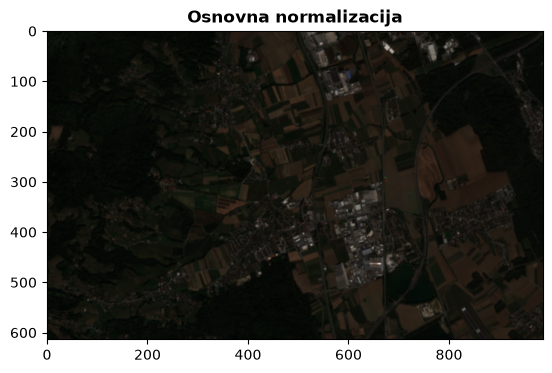

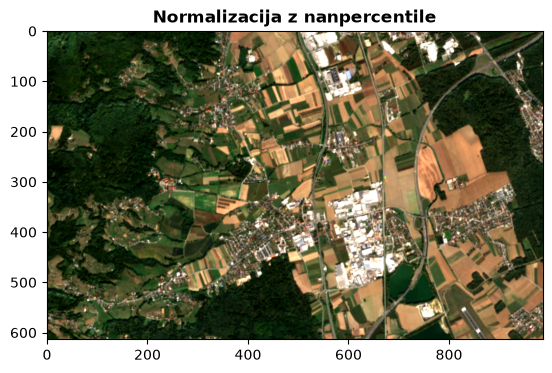

<Axes: title={'center': 'Normalizacija z nanpercentile'}>

In [15]:
import glob #knjižnica za iskanje fajlov(z wildcardi ipd.)
raster_dir=os.path.normpath(r"C:\KODA\Python\Rasterio\Browser_images")

rastri=sorted(glob.glob(os.path.join(raster_dir,"*.tiff")))
print(rastri)


fajli={
    "rdeč":rastri[2],
    "zelen":rastri[1],
    "moder":rastri[0],
    "nir":rastri[3],
}

def preberi_kanal(fajl_path):                     #samo spremeni kanal v array
    with rio.open(fajl_path) as dataset:
        return dataset.read(1)


kanali={}
for fajl in fajli:                               #uporabi preberi_kanal funkcijo na vseh različnih kanalih med fajli
    kanali[fajl]=preberi_kanal(fajli[fajl])

print(kanali)

rgb_kompozit=np.stack((kanali["rdeč"], kanali["zelen"],kanali["moder"]))

def osnovna_normalizacija(array: np.ndarray):                                #Zaradi visokih vrednosti je potrebna normalizacija
    return (array-array.min())/(array.max()-array.min())            #ta normalizacija je zgolj osnovna. Zato je vizualizacija temna; problem nastane, če se min in max zelo odmikata od povprečja.

def boljša_normalizacija(array:np.ndarray):
    array_min, array_max=np.nanpercentile(array, (2,98))  # nanpercentile vrne vrednost, ki je v 2 % in 98 % s tem da ignorira nan.
    return np.clip((array-array_min)/(array_max-array_min), 0, 1) # clip postavi min in max vrednosti v tem primeru 0 in 1

rgb_osnovno_normaliziran=osnovna_normalizacija(rgb_kompozit)
show(rgb_osnovno_normaliziran,title="Osnovna normalizacija")
show(boljša_normalizacija(rgb_kompozit), title="Normalizacija z nanpercentile")


#Končal na 50 min

## Shranjevanje kompozitov


In [ ]:

output_path=os.path.normpath(r"C:\KODA\Python\Rasterio")
kompozit_path=os.path.join(output_path,"kompozit.tif")   # tle se poimenuje fajl


with rio.open(fajli["moder"]) as src:
    meta=src.meta
    print(meta)
    meta.update({            #za posodabljanje meta podatkov
        "count": 3
        })
   
    print(meta)

    with rio.open(kompozit_path,"w",**meta) as dst:
        dst.write(rgb_kompozit)   # če se izvaža v qgis normalizacija ni potrebna


{'driver': 'GTiff', 'dtype': 'uint16', 'nodata': None, 'width': 987, 'height': 614, 'count': 1, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(8.978742234250332e-05, 0.0, 15.602688789367678,
       0.0, -6.181947723099745e-05, 46.523260804441584)}
{'driver': 'GTiff', 'dtype': 'uint16', 'nodata': None, 'width': 987, 'height': 614, 'count': 3, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(8.9787422

## Preprojekcija in izrez

In [32]:
import pyproj
import geopandas as gpd
import rasterio as rio
from rasterio.warp import  calculate_default_transform, reproject, Resampling
from rasterio.mask import mask
import os

### Preprojekcija koordinatnega sistema

In [49]:
path=os.path.normpath(r"C:\KODA\Python\Rasterio\kompozit.tif")
output_path=os.path.normpath(r"C:\KODA\Python\Rasterio")
preprjektiran_path=os.path.join(output_path,"prerpojektiran.tif") 


dst_crs=pyproj.CRS("EPSG:3794")  #željen crs
with rio.open(path)as src:
    print(src.crs)
    transform, width, height = calculate_default_transform(
        src.crs,
        dst_crs,
        src.width,
        src.height,
        *src.bounds
    )

    meta=src.meta.copy()
    meta.update({
        "crs" :dst_crs,
        "transform":transform,
        "width":width,
        "height":height,
    })
    print(transform, width, heigt)


    with rio.open(preprjektiran_path, "w", **meta) as dst:
        for i in range(1,src.count+1):
            reproject(
                source=rio.band(src,i),
                destination=rio.band(dst,i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=dst_crs,
                resampling=Resampling.nearest
            )


with rio.open(preprjektiran_path) as rp:
    print(rp.crs)

EPSG:4326
| 6.89, 0.00, 546239.55|
| 0.00,-6.89, 153966.50|
| 0.00, 0.00, 1.00| 993 621
EPSG:3794


### Izrez rastra na podlagi vektorja

In [ ]:
gpkg_path=os.path.normpath(r"C:\KODA\Python\Rasterio\Pivola.gpkg")
dem_path=os.path.normpath(r"C:\KODA\Python\Rasterio\Pivola.tif")
output_path=r"C:\KODA\Python\Rasterio"
izrez_path=os.path.join(output_path,"izrez.tif")

gdf=gpd.read_file(gpkg_path)
print(gdf)

with rio.open(dem_path) as src:
    if gdf.crs!=src.crs:
        gdf=gdf.to_crs(src.crs)

    oblike=gdf.geometry.values
    izrez_slike, izrez_slike_transform=mask(src,oblike)   # če hočeš invertirano: invert=True. Če želiš cropat: crop=True


    meta=src.meta.copy()
    meta.update({
        "height":izrez_slike.shape[1],
        "width":izrez_slike.shape[2],
        "transform":izrez_slike_transform
    })

    with rio.open(izrez_path,"w", **meta) as dst:
        dst.write(izrez_slike)
    

    id dodatno  verjetnost  Površina  \
0  NaN    None           3      1280   
1  NaN    None           3       764   
2  NaN    None           2        99   
3  NaN    None           2        31   
4  NaN    None           2        26   
..  ..     ...         ...       ...   
65 NaN    None           3        44   
66 NaN    None           1       109   
67 NaN    None           3       655   
68 NaN    None           2        32   
69 NaN    None           3       336   

                                             geometry  
0   MULTIPOLYGON (((548742.675 151893.469, 548743....  
1   MULTIPOLYGON (((548820.708 151880.337, 548820....  
2   MULTIPOLYGON (((548794.379 151952.092, 548793....  
3   MULTIPOLYGON (((548840.125 151956.009, 548839....  
4   MULTIPOLYGON (((548836.682 151947.411, 548836....  
..                                                ...  
65  MULTIPOLYGON (((548892.961 152208.134, 548893....  
66  MULTIPOLYGON (((548933.629 152041.448, 548933....  
67  MULTIPOLYGO